# DS3000 Project — Group 04
## Stage 1: Data Understanding and Baselines

Dataset: Plant Leaf Diseases

Proposed objective: Develop and compare machine-learning classifiers that predict the annotated plant/disease category of leaf images containing one distinct category.


### Dataset and prediction task

We use version 10 of the Plant Leaf Diseases dataset from Roboflow Universe, downloaded in COCO JSON format. The dataset contains images and annotations identifying plant and disease categories.

Our task is supervised multiclass classification. One observation is one retained image, and the target is the single distinct category assigned to that image’s annotations. Category IDs represent class names rather than numerical quantities, so the target has no physical measurement unit.

Although the original dataset includes bounding boxes for object detection, our current approach classifies whole images. We retain images containing exactly one distinct annotated category. An image may contain several leaves as long as their annotations all belong to the same category.

In [1]:
import json
from pathlib import Path

data_folder = Path("data/plant_leaf_diseases")

def load_annotations(split):
    with open(data_folder / split / "_annotations.coco.json") as f:
        return json.load(f)

train_annotations = load_annotations("train")
valid_annotations = load_annotations("valid")
test_annotations = load_annotations("test")

#opens jason file and loads it into a dictionary called train_annotations

print("Training images:", len(train_annotations["images"]))
print("Validation images:", len(valid_annotations["images"]))
print("Test images:", len(test_annotations["images"]))
print("Annotations:", len(train_annotations["annotations"]))

#categories definitions are identical in all splits.
for category in train_annotations["categories"]:
    print(category["id"], " ", category["name"])

Training images: 3426
Validation images: 428
Test images: 428
Annotations: 11885
0   leaves
1   Apple Scab Leaf
2   Apple leaf
3   Apple rust leaf
4   Bell_pepper leaf
5   Bell_pepper leaf spot
6   Blueberry leaf
7   Cherry leaf
8   Corn Gray leaf spot
9   Corn leaf blight
10   Corn rust leaf
11   Peach leaf
12   Potato leaf
13   Potato leaf early blight
14   Potato leaf late blight
15   Raspberry leaf
16   Soyabean leaf
17   Soybean leaf
18   Squash Powdery mildew leaf
19   Strawberry leaf
20   Tomato Early blight leaf
21   Tomato Septoria leaf spot
22   Tomato leaf
23   Tomato leaf bacterial spot
24   Tomato leaf late blight
25   Tomato leaf mosaic virus
26   Tomato leaf yellow virus
27   Tomato mold leaf
28   Tomato two spotted spider mites leaf
29   grape leaf
30   grape leaf black rot


### Data cleaning and missingness

We load the image records, annotations, and category definitions separately for the training, validation, and test sets. Each image is linked to its annotated categories using its image ID.

We standardize the labels “Soybean leaf” and “Soyabean leaf” as one soybean category by mapping category ID 17 to ID 16 in every split. This prevents spelling variants of the same intended category from being treated as separate prediction targets.

We exclude images with no annotated category because they do not provide a target label. We also exclude images with multiple distinct categories because our current task requires one target category per image. These exclusions limit our analysis to images suitable for single-label classification.

We check whether every referenced image file exists and whether Pillow can fully load it. Missing or unreadable images are excluded from the retained image-label dictionaries. These operations exclude observations from the analysis without deleting the original image files or modifying the source annotations.

The printed outputs report the category-filtered counts and the missing/corrupt-image counts for each split. We exclude images with unavailable labels rather than guessing replacement labels.

In [2]:
# Store the unique categories found in each image


def get_image_labels(annotations):
    image_labels = {}
    for image in annotations["images"]:
        image_id = image["id"]
        image_labels[image_id] = set()

    for annotation in annotations["annotations"]:
        image_id = annotation["image_id"]
        category_id = annotation["category_id"]

        if category_id == 17:
            category_id = 16  #merge two soya beans together

        image_labels[image_id].add(category_id)
    return image_labels

test_image_labels = get_image_labels(test_annotations)
valid_image_labels = get_image_labels(valid_annotations)
train_image_labels = get_image_labels(train_annotations)


# Count images by how many different categories they contain
def print_image_label_stats(image_labels):
    print("No category:", 
          sum(len(labels) == 0 for labels in image_labels.values()))

    print("Exactly one category:",
          sum(len(labels) == 1 for labels in image_labels.values()))

    print("Multiple categories:",
          sum(len(labels) > 1 for labels in image_labels.values()))
print_image_label_stats(test_image_labels)
print_image_label_stats(valid_image_labels)
print_image_label_stats(train_image_labels)

No category: 1
Exactly one category: 425
Multiple categories: 2
No category: 2
Exactly one category: 422
Multiple categories: 4
No category: 16
Exactly one category: 3384
Multiple categories: 26


### Existing data split

The downloaded dataset provides training, validation, and test sets with an approximately 80/10/10 split. We preserve these assignments and apply the same cleaning rules to each split. Excluding unsuitable images changes the retained counts and may slightly change the percentages. Final retained counts are reported after cleaning and duplicate checking.

In [3]:
# Remove images with no categories

def filter_single_category_images(image_labels):
    single_category_labels = {}
    excluded_ids = []
    for image_id, labels in image_labels.items():
        if len(labels) == 1:
            single_category_labels[image_id] = labels
        else:
            excluded_ids.append(image_id)
    return single_category_labels, excluded_ids


train_single_category_labels, train_excluded_ids = filter_single_category_images(train_image_labels)
test_single_category_labels, test_excluded_ids = filter_single_category_images(test_image_labels)
valid_single_category_labels, valid_excluded_ids = filter_single_category_images(valid_image_labels)

print("Training images with a single category:", len(train_single_category_labels))
print("Validation images with a single category:", len(valid_single_category_labels))
print("Test images with a single category:", len(test_single_category_labels))


# checking for corrupt or missing images
from PIL import Image

def check_images(name, annotations, data_folder):
    missing_image_ids = []
    corrupt_image_ids = []
    for image in annotations["images"]:
        image_id = image["id"]
        image_path = data_folder / name / image["file_name"]

        if not image_path.is_file():
            missing_image_ids.append(image_id)
            continue

        try:
            with Image.open(image_path) as img:
                img.load()

        except (OSError, ValueError):
            corrupt_image_ids.append(image_id)
    return missing_image_ids, corrupt_image_ids

train_missing_image_ids, train_corrupt_image_ids = check_images("train", train_annotations, data_folder)
test_missing_image_ids, test_corrupt_image_ids = check_images("test", test_annotations, data_folder)
valid_missing_image_ids, valid_corrupt_image_ids = check_images("valid", valid_annotations, data_folder)


print("Training missing images:", len(train_missing_image_ids))
print("Training corrupt images:", len(train_corrupt_image_ids))
print("Validation missing images:", len(valid_missing_image_ids))
print("Validation corrupt images:", len(valid_corrupt_image_ids))
print("Test missing images:", len(test_missing_image_ids))
print("Test corrupt images:", len(test_corrupt_image_ids))


#get rid of corrupt and missing images
for image_id in train_missing_image_ids + train_corrupt_image_ids:
    train_single_category_labels.pop(image_id, None)

for image_id in valid_missing_image_ids + valid_corrupt_image_ids:
    valid_single_category_labels.pop(image_id, None)

for image_id in test_missing_image_ids + test_corrupt_image_ids:
    test_single_category_labels.pop(image_id, None)

print("Final training images:", len(train_single_category_labels))
print("Final validation images:", len(valid_single_category_labels))
print("Final test images:", len(test_single_category_labels))

Training images with a single category: 3384
Validation images with a single category: 422
Test images with a single category: 425
Training missing images: 36
Training corrupt images: 0
Validation missing images: 4
Validation corrupt images: 0
Test missing images: 1
Test corrupt images: 0
Final training images: 3348
Final validation images: 418
Final test images: 424


In [4]:
import hashlib
from PIL import Image

splits = {
    "test": (test_annotations, test_single_category_labels),
    "valid": (valid_annotations, valid_single_category_labels),
    "train": (train_annotations, train_single_category_labels),
}

seen_images = {}
duplicates = []
conflicting_labels = []

# Check test first, then validation, then training.
# For overlaps, keep the evaluation example and exclude its training copy.
for split, (annotations, retained_labels) in splits.items():
    for image in sorted(annotations["images"], key=lambda item: item["id"]):
        image_id = image["id"]

        if image_id not in retained_labels:
            continue

        image_path = data_folder / split / image["file_name"]

        with Image.open(image_path) as img:
            rgb = img.convert("RGB")
            signature = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()

        category_id = next(iter(retained_labels[image_id]))

        if signature in seen_images:
            previous_split, previous_id, previous_category = seen_images[signature]

            duplicates.append(
                (split, image_id, previous_split, previous_id)
            )

            if category_id != previous_category:
                conflicting_labels.append(
                    (split, image_id, previous_split, previous_id)
                )
        else:
            seen_images[signature] = (split, image_id, category_id)

print("Duplicate copies found:", len(duplicates))
print("Duplicates with conflicting labels:", len(conflicting_labels))

# Resolve inconsistent labels before automatically excluding duplicates.
if conflicting_labels:
    print("Conflicting image pairs:", conflicting_labels)
    raise ValueError("Review conflicting duplicate labels before continuing.")

for split, image_id, previous_split, previous_id in duplicates:
    splits[split][1].pop(image_id, None)

for split, (_, retained_labels) in splits.items():
    removed = sum(item[0] == split for item in duplicates)
    print(
        f"{split}: removed {removed} duplicate copies; "
        f"{len(retained_labels)} images retained"
    )

Duplicate copies found: 0
Duplicates with conflicting labels: 0
test: removed 0 duplicate copies; 424 images retained
valid: removed 0 duplicate copies; 418 images retained
train: removed 0 duplicate copies; 3348 images retained


### Duplicate handling and retained observations

We check retained images for exact duplicate pixel content by converting each image to RGB and hashing its dimensions and pixel values. This allows identical decoded images to be detected even when their filenames differ.

For matching images with consistent labels, we retain one copy. We process test images first, followed by validation and training images, so an exact copy found in an evaluation set is excluded from training. Conflicting labels trigger an error for review before duplicate exclusion proceeds.

The outputs above show the duplicate copies excluded and the final retained counts for each split. All later plots and model inputs use these cleaned image-label dictionaries.

This check identifies exact pixel duplicates. It does not detect all related images, such as crops or brightness-adjusted versions of the same original.

In [5]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Figure 1: Category distribution of retained training images

This figure counts retained training images in each category after cleaning and duplicate exclusion. Each image contributes once to its category’s count.

The distribution helps assess how much training evidence is available for each category. Categories with fewer examples may be harder to learn reliably, while categories with more examples can have greater influence on overall accuracy.

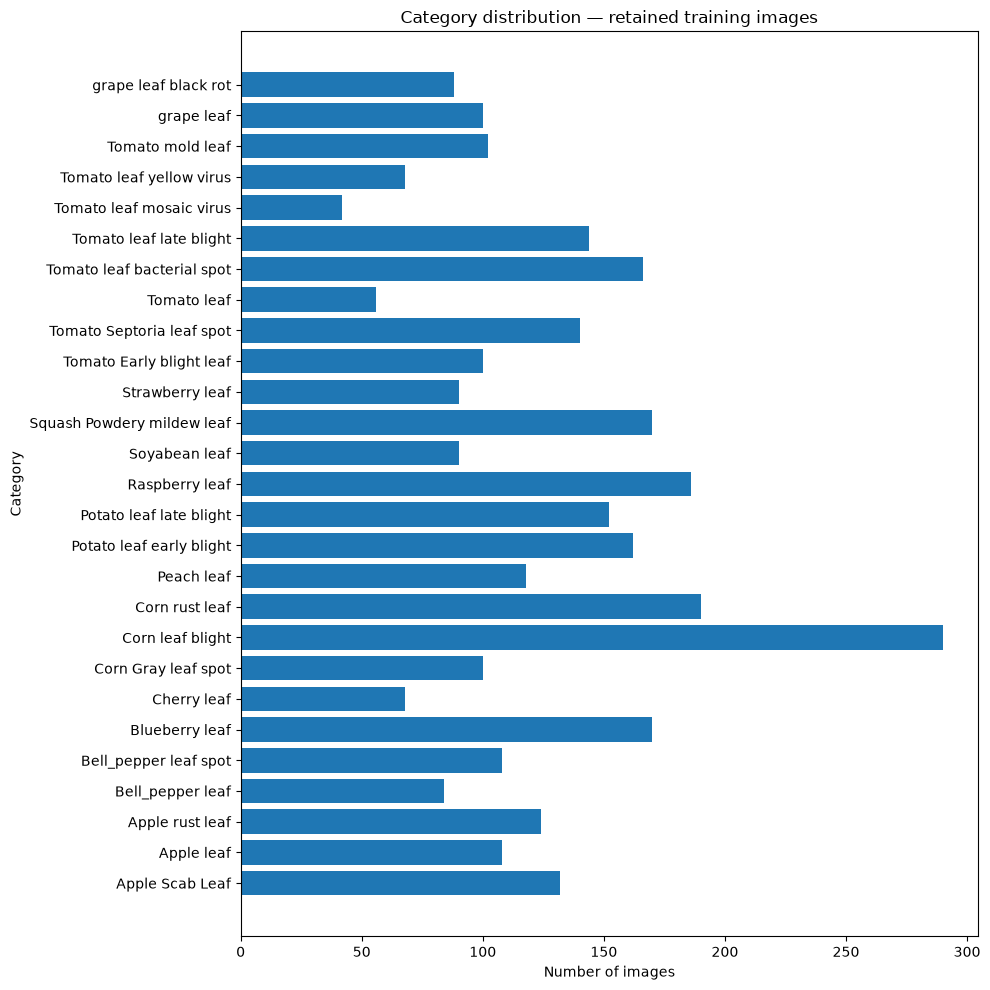

In [6]:
import matplotlib.pyplot as plt

category_counts = {}

for labels in train_single_category_labels.values():
    category_id = list(labels)[0]
    category_counts[category_id] = category_counts.get(category_id, 0) + 1

names = []
counts = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in category_counts:
        names.append(category["name"])
        counts.append(category_counts[category_id])

plt.figure(figsize=(10, 10))
plt.barh(names, counts)
plt.xlabel("Number of images")
plt.ylabel("Category")
plt.title("Category distribution — retained training images")
plt.tight_layout()
plt.show()

### Figure 1: Category distribution of retained training images

The training categories are unevenly represented. Corn leaf blight has considerably more images than other categories, while Tomato leaf mosaic virus has relatively few. This means the classifiers will have more training examples available for some categories than others.

This imbalance could lead to stronger performance on common categories and weaker performance on less represented ones. Overall accuracy could hide these differences, so we will also examine per-class results and macro-F1, which gives each category equal weight.

C:\Users\lucad\AppData\Local\Temp\ipykernel_24628\3392861431.py:37: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


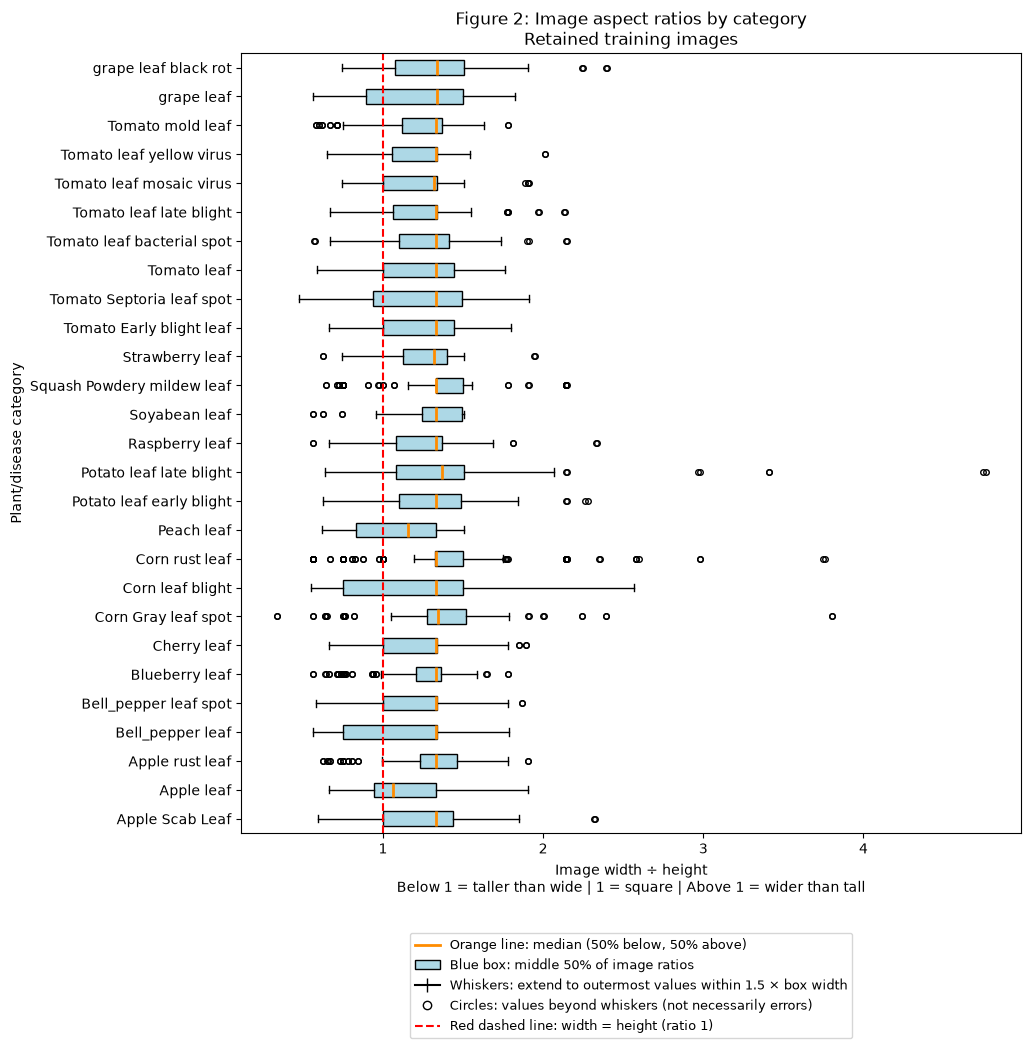

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

aspect_ratios = {}

for image in train_annotations["images"]:
    image_id = image["id"]

    # Only use images retained after cleaning and duplicate removal.
    if image_id not in train_single_category_labels:
        continue

    category_id = next(iter(train_single_category_labels[image_id]))
    image_path = data_folder / "train" / image["file_name"]

    with Image.open(image_path) as img:
        width, height = img.size

    aspect_ratios.setdefault(category_id, []).append(width / height)

# Match category names to their measurements.
category_names = []
ratio_groups = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in aspect_ratios:
        category_names.append(category["name"])
        ratio_groups.append(aspect_ratios[category_id])

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(13, 12))

ax.boxplot(
    ratio_groups,
    vert=False,
    tick_labels=category_names,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="darkorange", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="none",
        markeredgecolor="black",
        markersize=4
    )
)

# A ratio of 1 means the image's width equals its height.
ax.axvline(1, color="red", linestyle="--", linewidth=1.5)

legend_items = [
    Line2D(
        [0], [0], color="darkorange", linewidth=2,
        label="Orange line: median (50% below, 50% above)"
    ),
    Patch(
        facecolor="lightblue", edgecolor="black",
        label="Blue box: middle 50% of image ratios"
    ),
    Line2D(
        [0], [0], color="black", marker="|", markersize=10,
        label="Whiskers: extend to outermost values within 1.5 × box width"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="none",
        markerfacecolor="none", markeredgecolor="black",
        label="Circles: values beyond whiskers (not necessarily errors)"
    ),
    Line2D(
        [0], [0], color="red", linestyle="--",
        label="Red dashed line: width = height (ratio 1)"
    )
]

ax.set_xlabel(
    "Image width ÷ height\n"
    "Below 1 = taller than wide | 1 = square | Above 1 = wider than tall"
)
ax.set_ylabel("Plant/disease category")
ax.set_title(
    "Figure 2: Image aspect ratios by category\n"
    "Retained training images"
)

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    fontsize=9,
    frameon=True
)

# Leave room beneath the graph for the explanatory legend.
fig.subplots_adjust(left=0.30, bottom=0.27, top=0.92)

plt.show()

### Figure 2: Image aspect ratios by category

Most categories have median aspect ratios slightly above 1, indicating that their typical images are wider than they are tall. There is also variation within categories, with some unusually wide images. For example, Potato leaf late blight includes an image with an aspect ratio of approximately 4.7.

These differences matter when preparing fixed-size image inputs for the classifiers. Stretching every image into a square would distort wide or tall images. Resizing while preserving proportions and adding padding would avoid this distortion, although very wide images would occupy a smaller portion of the square and could lose fine detail when reduced.

The plot therefore supports considering resizing with padding as an initial preprocessing approach. Validation results will be needed to assess how well that approach works.